Starting analysis...

Solving 38 limit cycles with 8 workers...
Completed limit cycle for I_app = 64.0 (1/38)
Completed limit cycle for I_app = 72.0 (2/38)
Completed limit cycle for I_app = 80.0 (3/38)
Completed limit cycle for I_app = 88.0 (4/38)
Completed limit cycle for I_app = 104.0 (5/38)
Completed limit cycle for I_app = 96.0 (6/38)
Completed limit cycle for I_app = 112.0 (7/38)
Completed limit cycle for I_app = 120.0 (8/38)
Completed limit cycle for I_app = 128.0 (9/38)
Completed limit cycle for I_app = 136.0 (10/38)
Completed limit cycle for I_app = 144.0 (11/38)
Completed limit cycle for I_app = 152.0 (12/38)
Completed limit cycle for I_app = 160.0 (13/38)
Completed limit cycle for I_app = 168.0 (14/38)
Completed limit cycle for I_app = 176.0 (15/38)
Completed limit cycle for I_app = 184.0 (16/38)
Completed limit cycle for I_app = 192.0 (17/38)
Completed limit cycle for I_app = 232.0 (18/38)
Completed limit cycle for I_app = 208.0 (19/38)
Completed limit cycle for I_app = 200.

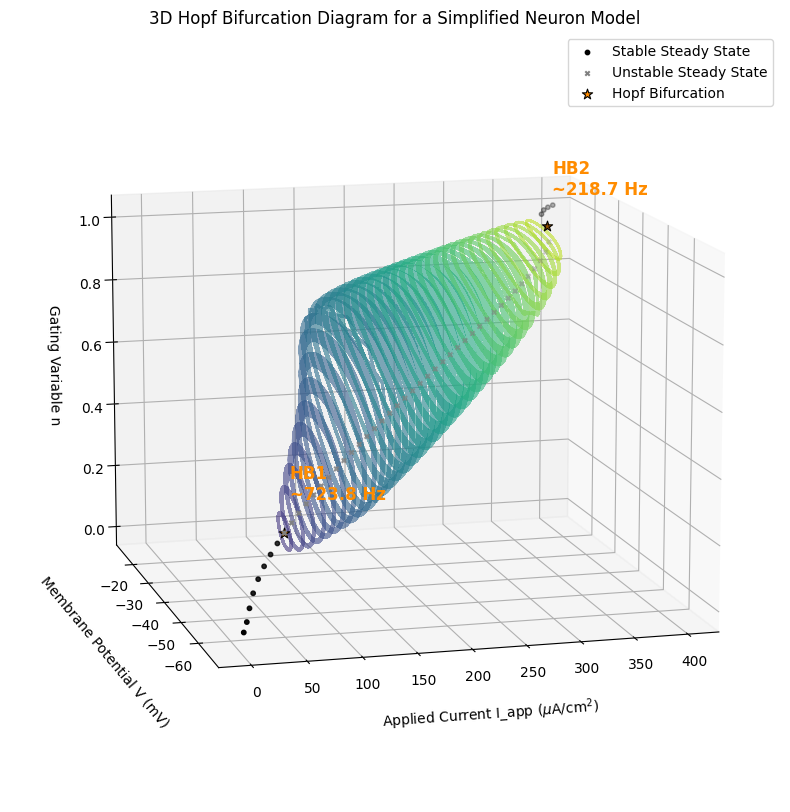

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import expit
from scipy.optimize import fsolve
from mpl_toolkits.mplot3d import Axes3D
import concurrent.futures
import os

NUM_WORKERS = os.cpu_count()

# --- 1. Define the System and its Derivatives ---

params = {
    'C_m': 1.0, 'g_Na': 20.0, 'g_K': 10.0, 'g_l': 8.0,
    'E_Na': 60.0, 'E_K': -90.0, 'E_l': -80.0, 'v1': -20.0,
    'k1': 15.0, 'v3': -45.0, 'k3': 5.0, 'phi': 2.0
}

# Gating functions (numerically stable)
def m_inf(V, p): return expit((V - p['v1']) / p['k1'])
def n_inf(V, p): return expit((V - p['v3']) / p['k3'])

# Derivatives of gating functions
def dm_inf_dV(V, p):
    m = m_inf(V, p)
    return m * (1 - m) / p['k1']

def dn_inf_dV(V, p):
    n = n_inf(V, p)
    return n * (1 - n) / p['k3']

# ODE function for the neuron model
def neuron_model_odes(y, p, I_app):
    V, n = y
    I_ion = (p['g_Na'] * m_inf(V, p) * (V - p['E_Na']) +
             p['g_K'] * n * (V - p['E_K']) +
             p['g_l'] * (V - p['E_l']))
    dVdt = (1 / p['C_m']) * (-I_ion + I_app)
    dndt = p['phi'] * (n_inf(V, p) - n)
    return [dVdt, dndt]

# Function to compute the Jacobian matrix
def calculate_jacobian(y, p, I_app):
    V, n = y
    dI_Na_dV = p['g_Na'] * (dm_inf_dV(V, p) * (V - p['E_Na']) + m_inf(V, p))
    dI_K_dV = p['g_K'] * n
    dI_l_dV = p['g_l']
    
    J11 = (1/p['C_m']) * -(dI_Na_dV + dI_K_dV + dI_l_dV)
    J12 = (1/p['C_m']) * -(p['g_K'] * (V - p['E_K']))
    J21 = p['phi'] * dn_inf_dV(V, p)
    J22 = -p['phi']
    
    return np.array([[J11, J12], [J21, J22]])

# Simulate the system to get limit cycles (No print statements here anymore)
def simulate_limit_cycle(args):
    I_app, steady_state, p = args
    y0_sim = steady_state + 0.1
    sol = solve_ivp(lambda t, y: neuron_model_odes(y, p, I_app), 
                    [0, 800], y0_sim, dense_output=True, rtol=1e-6, atol=1e-6)
    t_cycle = np.linspace(600, 800, 1000)
    y_cycle = sol.sol(t_cycle)
    return I_app, y_cycle[0], y_cycle[1]


# --- 2. Main Analysis Loop for 3D Diagram ---
if __name__ == '__main__':
    
    print("Starting analysis...\n")

    I_app_range = np.arange(0, 401, 8.0)
    all_ss = {'i': [], 'v': [], 'n': []}
    max_real_parts = []
    hopf_points = []
    tasks = []

    y_guess = [-60.0, 0.02]

    for i, I_app in enumerate(I_app_range):
        steady_state, info, ier, msg = fsolve(
            lambda y: neuron_model_odes(y, params, I_app), x0=y_guess, full_output=True
        )
        
        if ier != 1:
            print(f"  Warning: fsolve failed for I_app={I_app}")
            continue
            
        y_guess = steady_state
        all_ss['i'].append(I_app)
        all_ss['v'].append(steady_state[0])
        all_ss['n'].append(steady_state[1])
        
        J = calculate_jacobian(steady_state, params, I_app)
        eigenvalues = np.linalg.eigvals(J)
        current_max_real_part = np.max(np.real(eigenvalues))
        max_real_parts.append(current_max_real_part)

        if i > 0 and np.sign(max_real_parts[-2]) != np.sign(current_max_real_part):
            critical_eigenvalue = eigenvalues[np.argmax(np.real(eigenvalues))]
            omega = np.abs(np.imag(critical_eigenvalue))
            frequency_hz = (omega * 1000) / (2 * np.pi)
            hopf_points.append({'I_app': I_app, 'V': steady_state[0], 'n': steady_state[1], 'freq': frequency_hz})

        # Queue cycles if unstable
        if max_real_parts[-1] > 1e-4:
            tasks.append((I_app, steady_state, params))

    total_tasks = len(tasks)
    print(f"Solving {total_tasks} limit cycles with {NUM_WORKERS} workers...")
    limit_cycle_results = []

    # run with multiple threads
    with concurrent.futures.ProcessPoolExecutor(max_workers=NUM_WORKERS) as executor:
        futures = [executor.submit(simulate_limit_cycle, task) for task in tasks]
        
        for i, future in enumerate(concurrent.futures.as_completed(futures), 1):
            result = future.result()
            limit_cycle_results.append(result)
            print(f"Completed limit cycle for I_app = {result[0]:.1f} ({i}/{total_tasks})", flush=True)

    # --- 3. Plotting the 3D Diagram ---
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')

    stable_mask = np.array(max_real_parts) < 0
    unstable_mask = ~stable_mask

    ax.scatter(np.array(all_ss['i'])[stable_mask], np.array(all_ss['v'])[stable_mask], np.array(all_ss['n'])[stable_mask], 
               c='k', s=10, label='Stable Steady State')
    ax.scatter(np.array(all_ss['i'])[unstable_mask], np.array(all_ss['v'])[unstable_mask], np.array(all_ss['n'])[unstable_mask],
               c='gray', s=10, marker='x', label='Unstable Steady State')

    # Plot the limit cycles gathered from parallel processing
    for I_app, v_cycle, n_cycle in limit_cycle_results:
        i_app_cycle = np.full_like(v_cycle, I_app)
        ax.plot(i_app_cycle, v_cycle, n_cycle, lw=1.5, color=plt.cm.viridis(I_app / 400), alpha=0.6)

    for k, hp in enumerate(hopf_points):
        label = 'Hopf Bifurcation' if k == 0 else ""
        ax.scatter(hp['I_app'], hp['V'], hp['n'], c='darkorange', s=60, marker='*', 
                   edgecolor='k', linewidth=0.8, zorder=10, label=label)
        ax.text(hp['I_app'] + 5, hp['V'], hp['n'] + 0.1, f'HB{k+1}\n~{hp["freq"]:.1f} Hz', 
                color='darkorange', fontsize=12, weight='bold', zorder=10)

    ax.set_xlabel(r'Applied Current I_app ($\mu$A/cm$^2$)', labelpad=15)
    ax.set_ylabel('Membrane Potential V (mV)', labelpad=15)
    ax.set_zlabel('Gating Variable n', labelpad=10)
    ax.set_title('3D Hopf Bifurcation Diagram for a Simplified Neuron Model')
    ax.view_init(elev=12, azim=-105)
    ax.legend()

    print("\nAnalysis complete. Displaying plot.")
    plt.show()